# Automatidata: End-to-End NYC Yellow Taxi Analytics & Predictive Suite
### Inferential Statistics, Multiple Linear Regression for Fare Estimation & Gradient Boosting for Tip Prediction

---

## Executive Summary & Project Context

**Client:** New York City Taxi & Limousine Commission (NYC TLC)  
**Consultancy:** Automatidata Analytics Practice  
**Dataset:** 22,699 Yellow Taxi trip records (2017 representative sample from NYC TLC)  
**Engagement Objective:** Transform raw telematics data into an integrated analytical pipeline to evaluate passenger spending behavior, forecast trip fares, and classify tipping dynamics.

### Project Architecture & Analytical Lifecycle
1. **Phase 1: Exploratory Data Analysis & Demand Dynamics:** Audit data hygiene, remove physical telematics anomalies ($\le 0$ distance, duration, or fare) and extreme outliers ($>50$ miles, $>\$150$, or $>180$ minutes), and uncover urban mobility patterns across pickup hours, days of the week, and fare distributions.
2. **Phase 2: Two-Sample Observational Inference (Payment Method Analysis):** Conduct a two-sample Welch's t-test and effect-size analysis to evaluate differences in average fares between credit card and cash transactions, explicitly identifying observational selection biases.
3. **Phase 3: Multiple Linear Regression for Fare Pre-Estimation:** Engineer route-level benchmarks (`mean_distance` and `mean_duration`) strictly on training partitions with hierarchical zone fallbacks to prevent target leakage, evaluate OLS Gauss-Markov assumptions, and incorporate NYC TLC statutory flat rates (JFK Airport \$52.00 flat fare).
4. **Phase 4: Machine Learning for Generous Tip Classification:** Train and evaluate tree-based ensembles (**Random Forest** and **XGBoost Classifier**) with 5-Fold Stratified Cross-Validation to classify generous tippers ($\ge 20\%$) among card-paying passengers, benchmarked against a naive majority-class baseline (51.15%). Investigate the dominant influence of payment terminal vendor (`VendorID`) on recorded tip behavior.
5. **Phase 5: Strategic Translation & Decision Support:** Deliver evidence-based recommendations for digital payment infrastructure, in-cab terminal UX standardization, and upfront pricing transparency.

---
## 1. Environment Initialization & Library Imports

We import scientific computing libraries for data manipulation (`pandas`, `numpy`), date handling, inferential statistics (`scipy.stats`, `statsmodels`), and machine learning (`scikit-learn`, `xgboost`).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Modeling & Evaluation
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve,
    confusion_matrix, ConfusionMatrixDisplay
)

# Runtime Configuration
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 50)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette(['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd'])
%matplotlib inline

print("Automatidata Analytics Suite initialized successfully.")

Automatidata Analytics Suite initialized successfully.


---
## 2. Data Cleansing & Advanced Exploratory Data Analysis (EDA)

We ingest the 2017 Yellow Taxi Trip dataset and execute a systematic audit of data hygiene:
1. Auditing missing values, duplicate entries, and column data types.
2. Converting timestamps to datetime objects and calculating trip duration in minutes.
3. Filtering physically invalid records ($\le 0$ distance, $\le 0$ duration, $\le 0$ fare).
4. Removing extreme telematics outliers ($>50$ miles, $>\$150$ fare, or $>180$ minutes duration).
5. Mapping spatio-temporal demand patterns by hour of day, day of week, and trip distance.

In [2]:
# Ingest raw dataset with index column to prevent Unnamed: 0 leakage
df_raw = pd.read_csv("data/2017_Yellow_Taxi_Trip_Data.csv", index_col=0)

print(f"Raw dimensions: {df_raw.shape[0]:,} records x {df_raw.shape[1]} columns")
print(f"Missing values across dataset: {df_raw.isna().sum().sum()}")
print(f"Duplicate records: {df_raw.duplicated().sum()}")
df_raw.head()

Raw dimensions: 22,699 records x 17 columns
Missing values across dataset: 0
Duplicate records: 0


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
24870114,2,03/25/2017 8:55:43 AM,03/25/2017 9:09:47 AM,6,3.34,1,N,100,231,1,13.0,0.0,0.5,2.76,0.0,0.3,16.56
35634249,1,04/11/2017 2:53:28 PM,04/11/2017 3:19:58 PM,1,1.80,1,N,186,43,1,16.0,0.0,0.5,4.00,0.0,0.3,20.80
106203690,1,12/15/2017 7:26:56 AM,12/15/2017 7:34:08 AM,1,1.00,1,N,262,236,1,6.5,0.0,0.5,1.45,0.0,0.3,8.75
38942136,2,05/07/2017 1:17:59 PM,05/07/2017 1:48:14 PM,1,3.70,1,N,188,97,1,20.5,0.0,0.5,6.39,0.0,0.3,27.69
30841670,2,04/15/2017 11:32:20 PM,04/15/2017 11:49:03 PM,1,4.37,1,N,4,112,2,16.5,0.5,0.5,0.00,0.0,0.3,17.80


### Temporal Engineering & Anomaly Filtering

Raw telematics data captures meter errors, aborted trips, and positioning movements:
* **Duration Calculation:** Derived from pickup and dropoff timestamps in minutes.
* **Filter Conditions:** Trips must satisfy `trip_distance > 0`, `duration > 0`, and `fare_amount > 0`.
* **Outlier Boundaries:** Trips are bounded at 50 miles, \$150.00 fare, and 180 minutes duration to exclude multi-day meter errors while retaining standard airport and inter-borough trips.

In [3]:
# 1. Convert timestamps with explicit formatting
df = df_raw.copy()
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'], format='%m/%d/%Y %I:%M:%S %p')
df['tpep_dropoff_datetime'] = pd.to_datetime(df['tpep_dropoff_datetime'], format='%m/%d/%Y %I:%M:%S %p')

# 2. Derive trip duration in minutes
df['duration'] = (df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']).dt.total_seconds() / 60.0

# 3. Derive calendar features
df['day_name'] = df['tpep_pickup_datetime'].dt.day_name()
df['hour'] = df['tpep_pickup_datetime'].dt.hour

# 4. Audit anomalies before filtering
initial_count = len(df)
invalid_trips = df[(df['trip_distance'] <= 0) | (df['duration'] <= 0) | (df['fare_amount'] <= 0)]
extreme_outliers = df[(df['trip_distance'] > 50) | (df['fare_amount'] > 150) | (df['duration'] > 180)]

print(f"Total initial records: {initial_count:,}")
print(f"Zero/Negative distance, duration, or fare: {len(invalid_trips):,} ({len(invalid_trips)/initial_count*100:.2f}%)")
print(f"Extreme telematics outliers (>50 miles, >$150, or >3 hrs): {len(extreme_outliers):,} ({len(extreme_outliers)/initial_count*100:.2f}%)")

# 5. Apply validated filtering
df_clean = df[
    (df['trip_distance'] > 0) &
    (df['duration'] > 0) &
    (df['fare_amount'] > 0) &
    (df['trip_distance'] <= 50) &
    (df['fare_amount'] <= 150) &
    (df['duration'] <= 180)
].reset_index(drop=True)

print(f"Sanitized working records: {df_clean.shape[0]:,} ({len(df_clean)/initial_count*100:.2f}% retained)")

Total initial records: 22,699
Zero/Negative distance, duration, or fare: 165 (0.73%)
Extreme telematics outliers (>50 miles, >$150, or >3 hrs): 52 (0.23%)
Sanitized working records: 22,486 (99.06% retained)


### Spatio-Temporal Mobility & Demand Dynamics

We analyze demand fluctuations across the 24-hour daily cycle and days of the week, alongside empirical distributions of trip distances and fare receipts.

**Key Empirical Patterns from EDA:**
* **Diurnal Demand:** Demand reaches its lowest trough between 03:00 and 05:00, steadily climbing through midday before peaking during evening commute hours (18:00 - 19:00).
* **Weekly Rhythm:** Midweek to Friday exhibits sustained peak ridership, whereas Sundays and Mondays show lower trip volumes.
* **Distance Asymmetry:** Trip distances are heavily right-skewed, with the majority of city trips concentrated under 5 miles.
* **Statutory Airport Clustering:** In the fare vs. distance scatter plot, a prominent horizontal band at \$52.00 represents statutory flat-fare JFK Airport journeys.

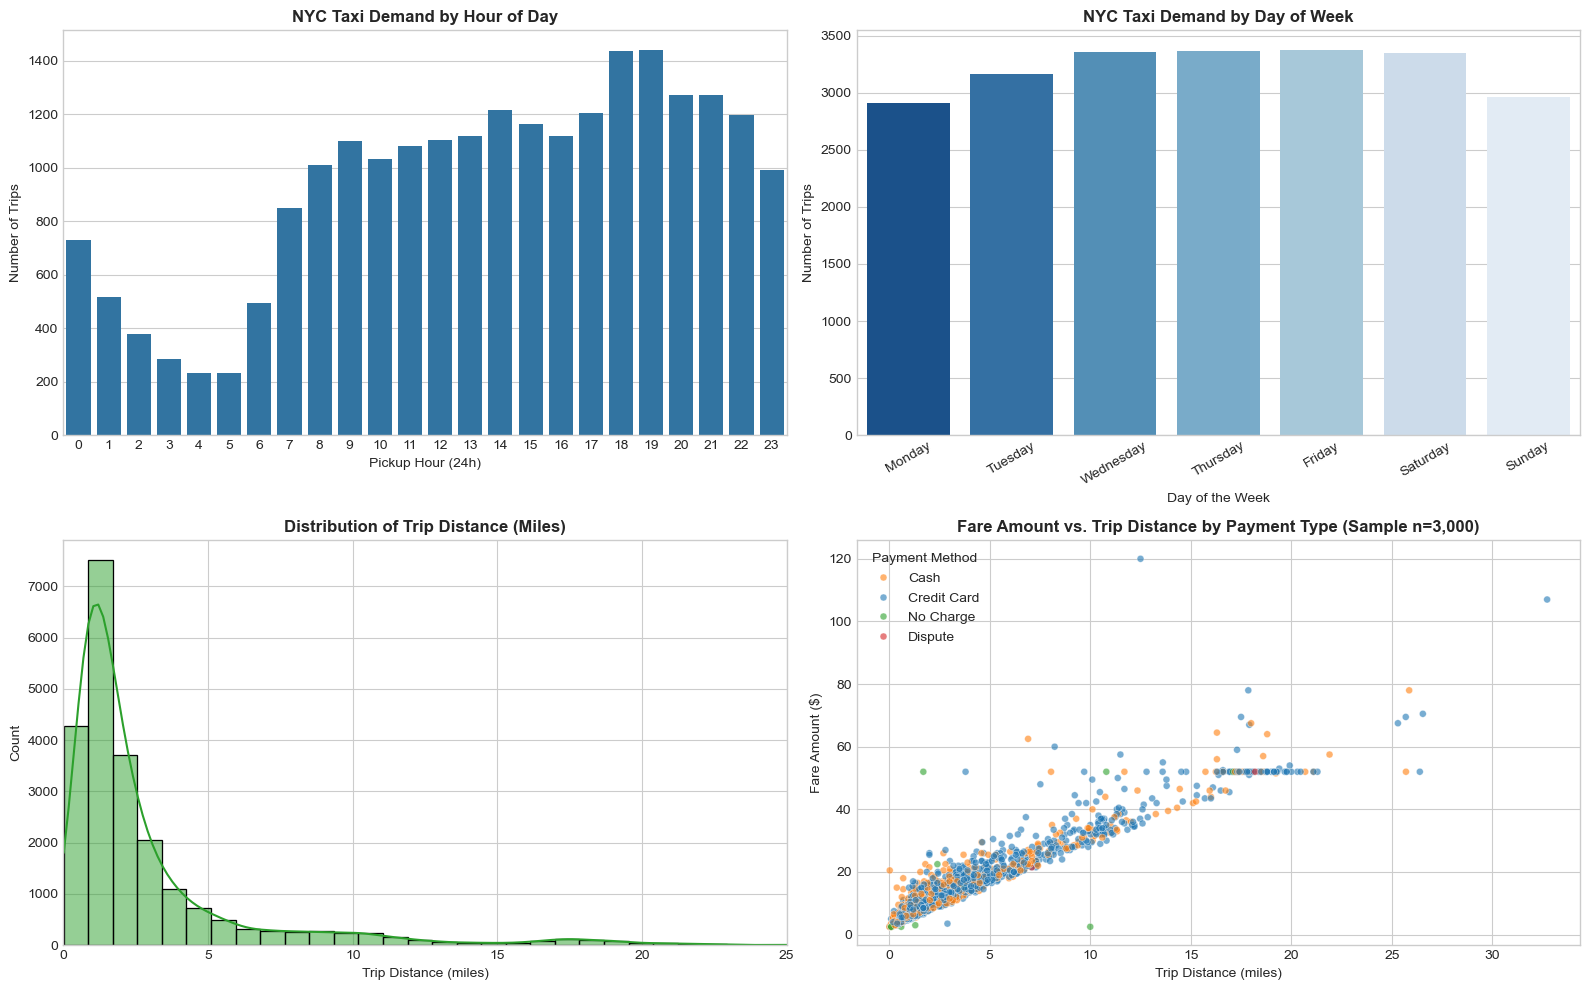

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Hourly Demand Distribution
sns.countplot(data=df_clean, x='hour', color='#1f77b4', ax=axes[0, 0])
axes[0, 0].set_title('NYC Taxi Demand by Hour of Day', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Pickup Hour (24h)')
axes[0, 0].set_ylabel('Number of Trips')

# 2. Day of Week Demand
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.countplot(data=df_clean, x='day_name', order=day_order, palette='Blues_r', ax=axes[0, 1])
axes[0, 1].set_title('NYC Taxi Demand by Day of Week', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Day of the Week')
axes[0, 1].set_ylabel('Number of Trips')
axes[0, 1].tick_params(axis='x', rotation=30)

# 3. Trip Distance Distribution
sns.histplot(df_clean['trip_distance'], bins=40, kde=True, color='#2ca02c', ax=axes[1, 0])
axes[1, 0].set_title('Distribution of Trip Distance (Miles)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Trip Distance (miles)')
axes[1, 0].set_xlim(0, 25)

# 4. Fare Amount vs. Trip Distance (Clean categorical mapping)
payment_map = {1: 'Credit Card', 2: 'Cash', 3: 'No Charge', 4: 'Dispute'}
sample_plot = df_clean.sample(min(3000, len(df_clean)), random_state=42).copy()
sample_plot['payment_method'] = sample_plot['payment_type'].map(payment_map)

sns.scatterplot(
    data=sample_plot,
    x='trip_distance', y='fare_amount', hue='payment_method',
    palette={'Credit Card': '#1f77b4', 'Cash': '#ff7f0e', 'No Charge': '#2ca02c', 'Dispute': '#d62728'},
    alpha=0.6, s=25, ax=axes[1, 1]
)
axes[1, 1].set_title('Fare Amount vs. Trip Distance by Payment Type (Sample n=3,000)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Trip Distance (miles)')
axes[1, 1].set_ylabel('Fare Amount ($)')
axes[1, 1].legend(title='Payment Method')

plt.tight_layout()
plt.show()

---
## 3. Two-Sample Statistical Inference: Credit Card vs. Cash Fare Distribution

### Business Question: Do Credit Card Customers Generate Higher Average Fares?
The TLC leadership seeks to evaluate whether passengers paying via credit card exhibit higher mean fares than cash passengers.

> **Methodological Note:** Because passengers self-select their payment method, this analysis constitutes an **observational two-sample comparison**, not a randomized controlled trial (A/B test). Differences reflect customer selection behavior (e.g., using cards for longer or corporate trips) rather than a causal effect of payment technology.

### Formal Hypothesis Formulation
- **Null Hypothesis ($H_0$):** There is no difference in the mean fare amount between credit card and cash transactions ($\mu_{\text{card}} = \mu_{\text{cash}}$).
- **Alternative Hypothesis ($H_1$):** There is a statistically significant difference in the mean fare amount between credit card and cash transactions ($\mu_{\text{card}} \neq \mu_{\text{cash}}$).
- **Significance Level ($\alpha$):** $\alpha = 0.05$ (two-tailed Welch's t-test, accommodating unequal sample sizes and variances).

In [5]:
# Isolate credit card (1) and cash (2) samples
card_fares = df_clean[df_clean['payment_type'] == 1]['fare_amount']
cash_fares = df_clean[df_clean['payment_type'] == 2]['fare_amount']

# Descriptive statistics
card_mean, card_std, card_n = card_fares.mean(), card_fares.std(), len(card_fares)
cash_mean, cash_std, cash_n = cash_fares.mean(), cash_fares.std(), len(cash_fares)
card_se = card_std / np.sqrt(card_n)
cash_se = cash_std / np.sqrt(cash_n)

print(f"Credit Card (Payment 1): N = {card_n:,} | Mean = ${card_mean:.2f} | Std = ${card_std:.2f} | SE = ${card_se:.2f}")
print(f"Cash        (Payment 2): N = {cash_n:,} | Mean = ${cash_mean:.2f} | Std = ${cash_std:.2f} | SE = ${cash_se:.2f}")

# Execute Welch's two-sample t-test (equal_var=False handles variance heterogeneity)
t_stat, p_val = stats.ttest_ind(card_fares, cash_fares, equal_var=False)

# Compute 95% Confidence Interval for difference in means
diff_mean = card_mean - cash_mean
diff_pct = (diff_mean / cash_mean) * 100
se_diff = np.sqrt((card_std**2 / card_n) + (cash_std**2 / cash_n))
ci_low = diff_mean - 1.96 * se_diff
ci_high = diff_mean + 1.96 * se_diff

# Compute Cohen's d effect size
pooled_std = np.sqrt(((card_n - 1)*card_std**2 + (cash_n - 1)*cash_std**2) / (card_n + cash_n - 2))
cohens_d = diff_mean / pooled_std

print(f"\n--- Statistical Test Results ---")
print(f"Welch's t-statistic: {t_stat:.4f}")
print(f"p-value:             {p_val:.4e}")
print(f"Mean Difference:     ${diff_mean:.2f} (+{diff_pct:.1f}% for credit card)")
print(f"95% CI of Diff:      [${ci_low:.2f}, ${ci_high:.2f}]")
print(f"Cohen's d:           {cohens_d:.4f} (small effect size)")

# Contextual check: Average trip distance by payment type
card_dist = df_clean[df_clean['payment_type'] == 1]['trip_distance'].mean()
cash_dist = df_clean[df_clean['payment_type'] == 2]['trip_distance'].mean()
print(f"\nTrip Distance Check: Card = {card_dist:.2f} miles | Cash = {cash_dist:.2f} miles")

Credit Card (Payment 1): N = 15,180 | Mean = $13.24 | Std = $10.76 | SE = $0.09
Cash        (Payment 2): N = 7,178 | Mean = $12.17 | Std = $10.44 | SE = $0.12

--- Statistical Test Results ---
Welch's t-statistic: 7.0660
p-value:             1.6671e-12
Mean Difference:     $1.07 (+8.8% for credit card)
95% CI of Diff:      [$0.77, $1.36]
Cohen's d:           0.1001 (small effect size)

Trip Distance Check: Card = 3.04 miles | Cash = 2.67 miles


### Statistical Interpretation & Takeaway

With a $p\text{-value} = 1.67 \times 10^{-12} \ll 0.001$, we **reject the null hypothesis ($H_0$)**.

Credit card passengers exhibit a statistically significantly higher mean fare amount than cash passengers:
* **Credit Card Mean:** **\$13.24** ($\pm \$0.09$ SE)
* **Cash Mean:** **\$12.17** ($\pm \$0.12$ SE)
* **Absolute Difference:** **+\$1.07** (+8.8% premium; 95% CI: [\$0.77, \$1.36])
* **Effect Size:** Cohen's $d = 0.10$

While the difference is statistically robust due to the large sample size ($N > 22,000$), the effect size ($d = 0.10$) is **small**. Crucially, trip distance is longer for card transactions (3.04 miles vs. 2.67 miles), confirming that passengers preferentially use credit cards for higher-fare, longer-distance journeys. This is a **selection effect**, not a causal relationship: promoting card payments will not increase fare per trip.

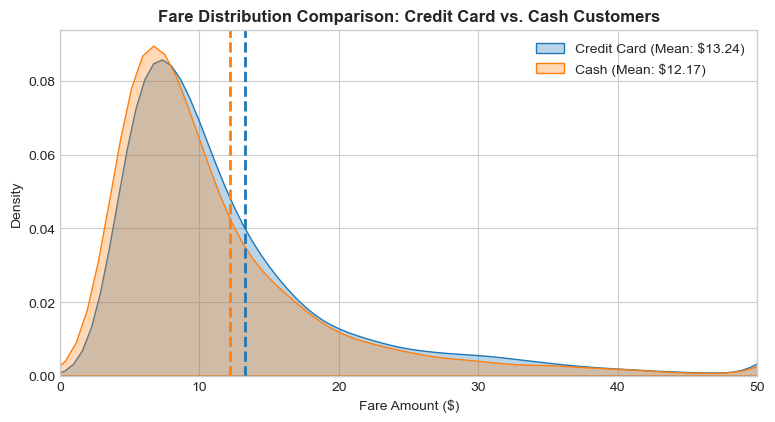

In [6]:
plt.figure(figsize=(9, 4.5))
sns.kdeplot(card_fares, label=f'Credit Card (Mean: ${card_mean:.2f})', color='#1f77b4', fill=True, alpha=0.3)
sns.kdeplot(cash_fares, label=f'Cash (Mean: ${cash_mean:.2f})', color='#ff7f0e', fill=True, alpha=0.3)
plt.axvline(card_mean, color='#1f77b4', linestyle='--', lw=2)
plt.axvline(cash_mean, color='#ff7f0e', linestyle='--', lw=2)
plt.title('Fare Distribution Comparison: Credit Card vs. Cash Customers', fontsize=12, fontweight='bold')
plt.xlabel('Fare Amount ($)')
plt.ylabel('Density')
plt.xlim(0, 50)
plt.legend(fontsize=10)
plt.show()

---
## 4. Multiple Linear Regression for Fare Prediction

The TLC requires an explainable model to estimate baseline trip fares before passengers embark.

### Leakage-Free Route Benchmark Engineering
Because real-time congestion and travel times cannot be known before a trip occurs, we engineer historical route-level benchmarks based on pickup-dropoff location pairs (`PULocationID`, `DOLocationID`):
* `mean_distance`: Historical average distance for the specific route pair.
* `mean_duration`: Historical average travel time (minutes) for the specific route pair.

> **Data Leakage Prevention:** Route aggregations are computed **strictly on the training partition** and then merged onto the test partition. Unseen test routes fall back to hierarchical zone-level means from training data (`PULocationID`), then to global training means as a final default. This prevents flat-fallback artifacts in residuals.

In [7]:
df_reg = df_clean.copy()

# Create unique route identifier
df_reg['pickup_dropoff'] = df_reg['PULocationID'].astype(str) + '_' + df_reg['DOLocationID'].astype(str)

reg_features = ['mean_duration', 'mean_distance', 'passenger_count']

# Partition train and test (80% / 20%) BEFORE route aggregations to prevent leakage
reg_train, reg_test = train_test_split(df_reg, test_size=0.20, random_state=42)

# 1. Exact route benchmarks computed strictly on training data
route_means = reg_train.groupby('pickup_dropoff').agg(
    mean_distance=('trip_distance', 'mean'),
    mean_duration=('duration', 'mean')
).reset_index()

# 2. Hierarchical fallback: pickup zone means from training data
zone_means = reg_train.groupby('PULocationID').agg(
    zone_mean_distance=('trip_distance', 'mean'),
    zone_mean_duration=('duration', 'mean')
).reset_index()

# 3. Global training fallback (last resort)
global_dist_mean = reg_train['trip_distance'].mean()
global_dur_mean = reg_train['duration'].mean()

# Apply hierarchical matching to TRAIN
reg_train = reg_train.merge(route_means, on='pickup_dropoff', how='left')
reg_train = reg_train.merge(zone_means, on='PULocationID', how='left')
reg_train['mean_distance'] = reg_train['mean_distance'].fillna(reg_train['zone_mean_distance']).fillna(global_dist_mean)
reg_train['mean_duration'] = reg_train['mean_duration'].fillna(reg_train['zone_mean_duration']).fillna(global_dur_mean)
reg_train.drop(columns=['zone_mean_distance', 'zone_mean_duration'], inplace=True)

# Apply hierarchical matching to TEST
reg_test = reg_test.merge(route_means, on='pickup_dropoff', how='left')
n_route_hit = reg_test['mean_distance'].notna().sum()
reg_test = reg_test.merge(zone_means, on='PULocationID', how='left')
reg_test['mean_distance'] = reg_test['mean_distance'].fillna(reg_test['zone_mean_distance']).fillna(global_dist_mean)
reg_test['mean_duration'] = reg_test['mean_duration'].fillna(reg_test['zone_mean_duration']).fillna(global_dur_mean)
reg_test.drop(columns=['zone_mean_distance', 'zone_mean_duration'], inplace=True)

# Report fallback coverage on test set
n_total_test = len(reg_test)
n_unseen_routes = n_total_test - n_route_hit
print(f"Test partition route coverage: {n_route_hit:,}/{n_total_test:,} ({n_route_hit/n_total_test*100:.1f}%) matched by exact route")
print(f"Unseen routes falling back to zone/global mean: {n_unseen_routes:,} ({n_unseen_routes/n_total_test*100:.1f}%)")

# Apply training-derived benchmarks to full df_reg for downstream consistency
df_reg = df_reg.merge(route_means, on='pickup_dropoff', how='left')
df_reg = df_reg.merge(zone_means, on='PULocationID', how='left')
df_reg['mean_distance'] = df_reg['mean_distance'].fillna(df_reg['zone_mean_distance']).fillna(global_dist_mean)
df_reg['mean_duration'] = df_reg['mean_duration'].fillna(df_reg['zone_mean_duration']).fillna(global_dur_mean)
df_reg.drop(columns=['zone_mean_distance', 'zone_mean_duration'], inplace=True)

print("\nRoute benchmark features engineered with hierarchical fallback:")
reg_train[['pickup_dropoff', 'trip_distance', 'mean_distance', 'duration', 'mean_duration', 'fare_amount']].head()

Test partition route coverage: 4,118/4,498 (91.6%) matched by exact route
Unseen routes falling back to zone/global mean: 380 (8.4%)

Route benchmark features engineered with hierarchical fallback:


,pickup_dropoff,trip_distance,mean_distance,duration,mean_duration,fare_amount
0,261_68,2.90,3.000000,15.266667,16.954167,12.5
1,137_163,2.06,1.990000,6.966667,14.145833,8.0
2,90_114,0.78,1.361111,8.283333,9.416667,7.0
3,107_141,2.70,2.992000,7.233333,12.890000,9.5
4,141_233,1.00,1.346667,5.050000,8.388889,5.5


### Mathematical Verification of OLS Assumptions

Before deploying Multiple Linear Regression, we evaluate the **Gauss-Markov conditions**:
1. **Linearity:** Linear relationship between route features and fare receipts.
2. **Multicollinearity:** Assessed via the Variance Inflation Factor (VIF), adding an intercept constant.
3. **Residual Normality & Distribution:** Examined via Q-Q plots and residual distributions.
4. **Homoscedasticity:** Constant residual variance across fitted values.

In [8]:
# Feature matrix and targets
X_train_r = reg_train[reg_features]
y_train_r = reg_train['fare_amount']
X_test_r = reg_test[reg_features]
y_test_r = reg_test['fare_amount']

# Calculate Variance Inflation Factor (VIF) with intercept constant
X_vif = sm.add_constant(X_train_r)
vif_data = pd.DataFrame({
    'Feature': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
print("Variance Inflation Factor (VIF) Diagnostics (with Intercept):")
print(vif_data)

# Fit Multiple Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train_r, y_train_r)

# Evaluate on held-out test set
y_pred_r = lr_model.predict(X_test_r)

r2 = r2_score(y_test_r, y_pred_r)
mae = mean_absolute_error(y_test_r, y_pred_r)
rmse = np.sqrt(mean_squared_error(y_test_r, y_pred_r))

print(f"\n--- OLS Regression Performance (Test Partition) ---")
print(f"R^2 Score: {r2:.4f}")
print(f"MAE:      ${mae:.4f}")
print(f"RMSE:     ${rmse:.4f}")

# Model Coefficients
coef_df = pd.DataFrame({
    'Feature': ['Intercept'] + reg_features,
    'Coefficient': [lr_model.intercept_] + list(lr_model.coef_)
})
print(coef_df)

Variance Inflation Factor (VIF) Diagnostics (with Intercept):
           Feature       VIF
0            const  5.314822
1    mean_duration  4.174259
2    mean_distance  4.174140
3  passenger_count  1.000120

--- OLS Regression Performance (Test Partition) ---
R^2 Score: 0.6690
MAE:      $3.1514
RMSE:     $6.1693
           Feature  Coefficient
0        Intercept     2.739151
1    mean_duration     0.283128
2    mean_distance     2.066865
3  passenger_count     0.021147


### OLS Diagnostics: Residuals vs. Fitted & Normality

We inspect residuals on the held-out test partition to assess homoscedasticity and distribution symmetry.

> **Diagnostic Finding:** Residuals exhibit a heavy upper tail in the Q-Q plot and two prominent structural patterns: (1) a vertical concentration near the fallback prediction value, produced by unseen routes that receive zone/global fallback averages, and (2) a downward diagonal around fitted values of \$40 - \$60 corresponding to statutory JFK Airport flat-fare trips that the linear model systematically misestimates.

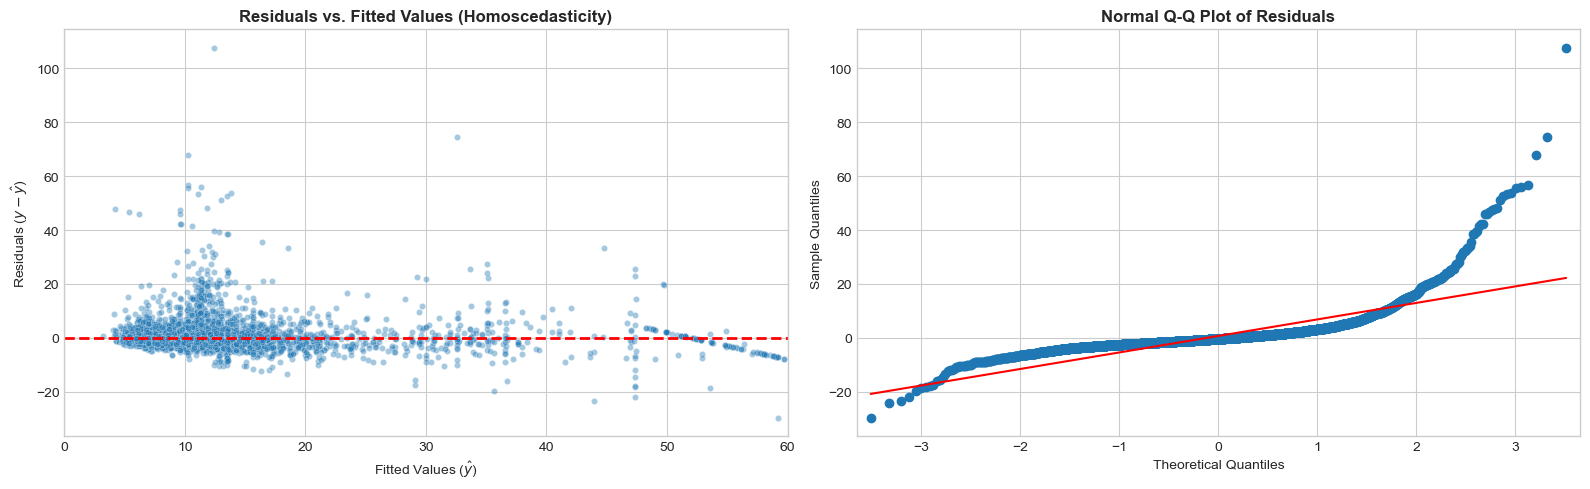

In [9]:
residuals = y_test_r - y_pred_r

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Homoscedasticity check
sns.scatterplot(x=y_pred_r, y=residuals, alpha=0.4, color='#1f77b4', s=20, ax=ax1)
ax1.axhline(0, color='red', linestyle='--', lw=2)
ax1.set_title('Residuals vs. Fitted Values (Homoscedasticity)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Fitted Values ($\hat{y}$)')
ax1.set_ylabel('Residuals ($y - \hat{y}$)')
ax1.set_xlim(0, 60)

# Normality check (Q-Q plot)
sm.qqplot(residuals, line='s', ax=ax2)
ax2.set_title('Normal Q-Q Plot of Residuals', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### TLC Regulatory Rule Integration: JFK Airport Flat Rate

Under NYC TLC statutory rules, trips between Manhattan and JFK International Airport operate under a mandatory **\$52.00 flat fare** (`RatecodeID == 2`).

Because standard linear regression cannot infer jurisdictional fixed-fee schedules from continuous mileage alone, we integrate this statutory rule by overriding predictions for JFK trips with \$52.00 on the held-out test partition.

In [10]:
# Named regulatory constant
JFK_FLAT_FARE = 52.00

# 1. Apply rule strictly to held-out test partition
y_pred_test_jfk = y_pred_r.copy()
jfk_test_mask = (reg_test['RatecodeID'] == 2)
y_pred_test_jfk[jfk_test_mask] = JFK_FLAT_FARE

# Evaluate impact on test data
test_jfk_r2 = r2_score(y_test_r, y_pred_test_jfk)
test_jfk_mae = mean_absolute_error(y_test_r, y_pred_test_jfk)
test_jfk_rmse = np.sqrt(mean_squared_error(y_test_r, y_pred_test_jfk))

print(f"Held-out test JFK trips adjusted: {jfk_test_mask.sum():,} records")
print(f"Test OLS Baseline:            R^2 = {r2:.4f} | MAE = ${mae:.4f} | RMSE = ${rmse:.4f}")
print(f"Test OLS + Statutory JFK:     R^2 = {test_jfk_r2:.4f} | MAE = ${test_jfk_mae:.4f} | RMSE = ${test_jfk_rmse:.4f}")

Held-out test JFK trips adjusted: 98 records
Test OLS Baseline:            R^2 = 0.6690 | MAE = $3.1514 | RMSE = $6.1693
Test OLS + Statutory JFK:     R^2 = 0.7145 | MAE = $2.9591 | RMSE = $5.7292


---
## 5. Generous Tip Classification with Machine Learning

Classifying whether a ride is likely to yield a **generous tip ($\ge 20\%$)** provides operational intelligence for understanding tipping dynamics across the NYC taxi fleet.

### Domain Constraints on TLC Tip Records:
1. **Card-only recording:** In NYC TLC data, tips are only electronically logged for **credit card transactions** (`payment_type == 1`). Cash tips are unrecorded by in-cab meters (logged as \$0.00). Tip models are therefore trained exclusively on credit card trips to avoid target distortion.
2. **Post-trip payment selection:** Because payment method is determined at trip completion, these models analyze tipping behavior among card payers retrospectively.

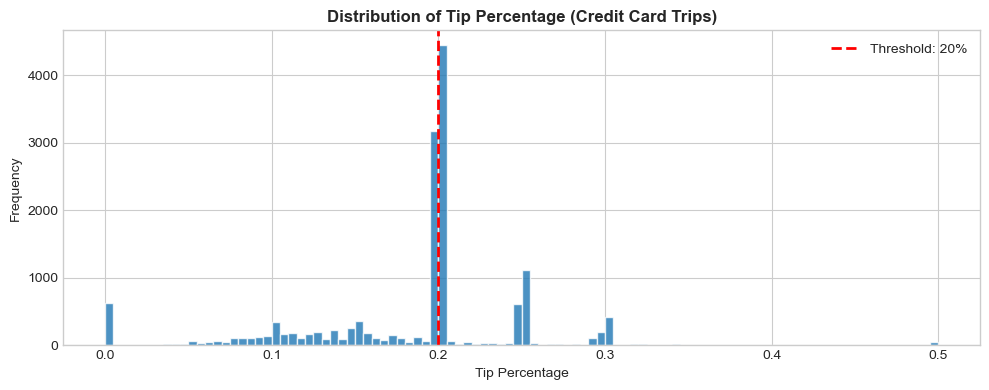

Trips with tip_percent at exactly ~20.00%: 4,452 (29.3% of card trips)

Generous Tip Class Breakdown:
Standard Tip (<20%):   7,764 (51.15%)
Generous Tip (>=20%):  7,416 (48.85%)
Naive Accuracy Baseline (always predict majority): 51.15%


In [11]:
# Filter to credit card transactions
df_ml = df_reg[df_reg['payment_type'] == 1].copy()

# Compute tip percentage relative to base fare & extras (excluding tip itself)
df_ml['tip_percent'] = (df_ml['tip_amount'] / (df_ml['total_amount'] - df_ml['tip_amount'])).round(4)

# Visualize tip_percent distribution to justify threshold selection
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(df_ml['tip_percent'].clip(0, 0.50), bins=100, color='#1f77b4', edgecolor='white', alpha=0.8)
ax.axvline(0.20, color='red', linestyle='--', lw=2, label='Threshold: 20%')
ax.set_title('Distribution of Tip Percentage (Credit Card Trips)', fontsize=12, fontweight='bold')
ax.set_xlabel('Tip Percentage')
ax.set_ylabel('Frequency')
ax.legend()
plt.tight_layout()
plt.show()

# Report mass at exactly 20%
exact_20 = ((df_ml['tip_percent'] >= 0.1999) & (df_ml['tip_percent'] <= 0.2001)).sum()
print(f"Trips with tip_percent at exactly ~20.00%: {exact_20:,} ({exact_20/len(df_ml)*100:.1f}% of card trips)")

# Define binary target: Generous Tip (>= 20%)
df_ml['generous'] = (df_ml['tip_percent'] >= 0.20).astype(int)

# Inspect target distribution and naive majority baseline
class_counts = df_ml['generous'].value_counts()
class_pcts = df_ml['generous'].value_counts(normalize=True) * 100
majority_class_pct = class_pcts.max()

print(f"\nGenerous Tip Class Breakdown:")
print(f"Standard Tip (<20%):   {class_counts[0]:,} ({class_pcts[0]:.2f}%)")
print(f"Generous Tip (>=20%):  {class_counts[1]:,} ({class_pcts[1]:.2f}%)")
print(f"Naive Accuracy Baseline (always predict majority): {majority_class_pct:.2f}%")

### Feature Engineering & Data Leakage Prevention

To ensure models operate strictly with pre-trip information, post-trip telemetry and financial totals are excluded:
* **Excluded (Target & Telematics Leakage):** `Unnamed: 0`, `tip_amount`, `total_amount`, `tip_percent`, `fare_amount`, `tolls_amount`, `extra`, `mta_tax`, `improvement_surcharge`, `trip_distance`, `duration`, `store_and_fwd_flag`, `payment_type`, `predicted_fare`.

* **Engineered Pre-Trip Features:**
  * Rush hour windows: `am_rush` (06:00 - 10:00), `daytime` (10:00 - 16:00), `pm_rush` (16:00 - 20:00), `nighttime` (20:00 - 06:00).
  * Day of week and pickup month indicators (capturing seasonal demand).
  * Route benchmarks: `mean_distance`, `mean_duration` (derived from training partitions).
  * **Categorical Encoding:** Nominal identifiers (`VendorID`, `RatecodeID`, `PULocationID`, `DOLocationID`) are one-hot encoded into dummy indicators.

In [12]:
# 1. Rush hour indicators
df_ml['am_rush'] = ((df_ml['hour'] >= 6) & (df_ml['hour'] < 10)).astype(int)
df_ml['daytime'] = ((df_ml['hour'] >= 10) & (df_ml['hour'] < 16)).astype(int)
df_ml['pm_rush'] = ((df_ml['hour'] >= 16) & (df_ml['hour'] < 20)).astype(int)
df_ml['nighttime'] = ((df_ml['hour'] >= 20) | (df_ml['hour'] < 6)).astype(int)

# 2. Temporal calendar features
df_ml['day'] = df_ml['tpep_pickup_datetime'].dt.day_name().str.lower()
df_ml['month'] = df_ml['tpep_pickup_datetime'].dt.month_name().str.lower()

# 3. Cast nominal IDs to string for dummy encoding
cols_to_str = ['VendorID', 'RatecodeID', 'PULocationID', 'DOLocationID']
for col in cols_to_str:
    df_ml[col] = df_ml[col].astype('str')

# 4. Strict leakage prevention: drop target, post-trip telematics, AND predicted_fare
#    predicted_fare is excluded because it is a near-proxy for fare_amount (R^2 ~0.64-0.69)
#    and was generated with a regression model trained on overlapping partitions.
drop_cols = [
    'Unnamed: 0', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
    'trip_distance', 'duration', 'store_and_fwd_flag', 'payment_type',
    'fare_amount', 'extra', 'mta_tax', 'tip_amount',
    'tolls_amount', 'improvement_surcharge', 'total_amount',
    'tip_percent', 'day_name', 'hour', 'pickup_dropoff',
    'predicted_fare'
]
df_features = df_ml.drop(columns=[c for c in drop_cols if c in df_ml.columns])

# 5. One-hot dummy encoding
df_dummies = pd.get_dummies(df_features, drop_first=True)

# 6. Feature matrix X and target y
X_ml = df_dummies.drop(columns=['generous'])
y_ml = df_dummies['generous']

# 7. Stratified Train-Test Split (80% Train, 20% Test)
X_train_ml, X_test_ml, y_train_ml, y_test_ml = train_test_split(
    X_ml, y_ml, test_size=0.20, stratify=y_ml, random_state=42
)

print(f"ML Feature Space: {X_ml.shape[1]} features")
print(f"Training partition: {X_train_ml.shape[0]:,} samples | Test partition: {X_test_ml.shape[0]:,} samples")

ML Feature Space: 341 features
Training partition: 12,144 samples | Test partition: 3,036 samples


---
## 6. Model Development, Tuning & Cross-Validation

We evaluate two tree-based ensembles using **5-Fold Stratified Cross-Validation**, benchmarked against a naive majority-class baseline:
1. **Majority Baseline Classifier:** Predicts the most frequent class (standard tip, 51.15%) to establish the minimum performance floor.
2. **Random Forest Classifier:** Bagging ensemble tuned over depth, tree count, and leaf constraints.
3. **XGBoost Classifier:** Regularized gradient boosting optimizing log-loss across depth and child weight parameters.

In [13]:
def evaluate_classifier(name, y_true, y_pred, y_proba):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auc = roc_auc_score(y_true, y_proba)
    
    return pd.DataFrame({
        'Model': [name],
        'Accuracy': [round(acc, 4)],
        'Precision': [round(prec, 4)],
        'Recall': [round(rec, 4)],
        'F1-Score': [round(f1, 4)],
        'ROC-AUC': [round(auc, 4)]
    })

ml_scoreboard = pd.DataFrame()

# Establish naive majority baseline
dummy_clf = DummyClassifier(strategy='most_frequent')
dummy_clf.fit(X_train_ml, y_train_ml)
y_pred_dummy = dummy_clf.predict(X_test_ml)
y_proba_dummy = dummy_clf.predict_proba(X_test_ml)[:, 1]

dummy_results = evaluate_classifier('Baseline (Majority Class)', y_test_ml, y_pred_dummy, y_proba_dummy)
ml_scoreboard = pd.concat([ml_scoreboard, dummy_results], ignore_index=True)
print(dummy_results)

                       Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
0  Baseline (Majority Class)    0.5115        0.0     0.0       0.0      0.5


In [14]:
rf_clf = RandomForestClassifier(random_state=42)

rf_params = {
    'max_depth': [None, 15],
    'max_features': ['sqrt', 20],
    'min_samples_leaf': [1, 2],
    'min_samples_split': [2, 5],
    'n_estimators': [100, 150]
}

rf_grid = GridSearchCV(
    estimator=rf_clf,
    param_grid=rf_params,
    scoring='f1',
    cv=5,
    n_jobs=-1
)

rf_grid.fit(X_train_ml, y_train_ml)
best_rf = rf_grid.best_estimator_

print('Random Forest - Best Parameters:', rf_grid.best_params_)
print(f'Random Forest - Best 5-Fold CV F1: {rf_grid.best_score_:.4f}')

y_pred_rf = best_rf.predict(X_test_ml)
y_proba_rf = best_rf.predict_proba(X_test_ml)[:, 1]

rf_results = evaluate_classifier('Random Forest (Tuned)', y_test_ml, y_pred_rf, y_proba_rf)
ml_scoreboard = pd.concat([ml_scoreboard, rf_results], ignore_index=True)
print(rf_results)

Random Forest - Best Parameters: {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
Random Forest - Best 5-Fold CV F1: 0.7373
                   Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
0  Random Forest (Tuned)     0.723     0.6884   0.791    0.7361    0.731


In [15]:
xgb_clf = XGBClassifier(
    objective='binary:logistic',
    random_state=42,
    eval_metric='logloss'
)

xgb_params = {
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5],
    'min_child_weight': [2, 4],
    'n_estimators': [100, 150]
}

xgb_grid = GridSearchCV(
    estimator=xgb_clf,
    param_grid=xgb_params,
    scoring='f1',
    cv=5,
    n_jobs=-1
)

xgb_grid.fit(X_train_ml, y_train_ml)
best_xgb = xgb_grid.best_estimator_

print('XGBoost - Best Parameters:', xgb_grid.best_params_)
print(f'XGBoost - Best 5-Fold CV F1: {xgb_grid.best_score_:.4f}')

y_pred_xgb = best_xgb.predict(X_test_ml)
y_proba_xgb = best_xgb.predict_proba(X_test_ml)[:, 1]

xgb_results = evaluate_classifier('XGBoost Classifier', y_test_ml, y_pred_xgb, y_proba_xgb)
ml_scoreboard = pd.concat([ml_scoreboard, xgb_results], ignore_index=True)
print(xgb_results)

XGBoost - Best Parameters: {'learning_rate': 0.05, 'max_depth': 3, 'min_child_weight': 4, 'n_estimators': 100}
XGBoost - Best 5-Fold CV F1: 0.7384
                Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
0  XGBoost Classifier    0.7233      0.687  0.7964    0.7377   0.7357


---
## 7. Model Evaluation & Decision Matrix

We benchmark classifier performance on the held-out test split using comparative ROC curves, Precision-Recall curves, and confusion matrices.

=== FINAL CLASSIFICATION BENCHMARK (TEST DATA) ===
                    Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Baseline (Majority Class)    0.5115     0.0000  0.0000    0.0000   0.5000
    Random Forest (Tuned)    0.7230     0.6884  0.7910    0.7361   0.7310
       XGBoost Classifier    0.7233     0.6870  0.7964    0.7377   0.7357

Model Comparison: Technical Tie between Random Forest and XGBoost (AUC delta = 0.0047)


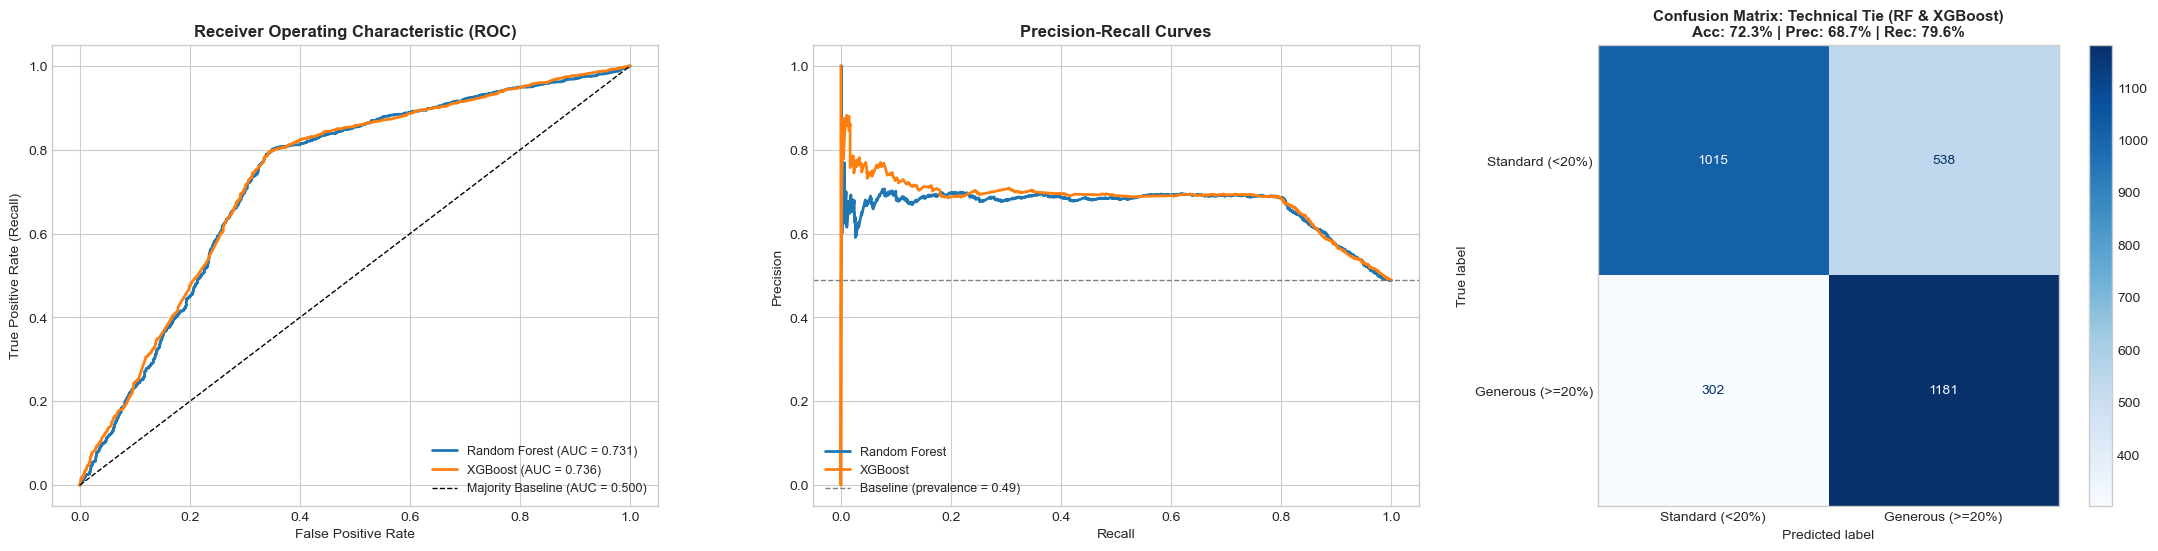

In [16]:
print("=== FINAL CLASSIFICATION BENCHMARK (TEST DATA) ===")
print(ml_scoreboard.to_string(index=False))

# Dynamic champion evaluation based on ROC-AUC
rf_auc = rf_results["ROC-AUC"].values[0]
xgb_auc = xgb_results["ROC-AUC"].values[0]
auc_gap = abs(rf_auc - xgb_auc)

if auc_gap < 0.005:
    champion_name = "Technical Tie (RF & XGBoost)"
    champion_pred = y_pred_xgb
    champion_results = xgb_results
    print(f"\nModel Comparison: Technical Tie between Random Forest and XGBoost (AUC delta = {auc_gap:.4f})")
elif xgb_auc >= rf_auc:
    champion_name = "XGBoost Classifier"
    champion_pred = y_pred_xgb
    champion_results = xgb_results
    print(f"\nChampion: {champion_name} (AUC = {xgb_auc:.4f})")
else:
    champion_name = "Random Forest (Tuned)"
    champion_pred = y_pred_rf
    champion_results = rf_results
    print(f"\nChampion: {champion_name} (AUC = {rf_auc:.4f})")

fig, axes = plt.subplots(1, 3, figsize=(22, 5.5))

# 1. Comparative ROC Curves
fpr_rf, tpr_rf, _ = roc_curve(y_test_ml, y_proba_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test_ml, y_proba_xgb)

axes[0].plot(fpr_rf, tpr_rf, lw=2, label=f'Random Forest (AUC = {rf_auc:.3f})')
axes[0].plot(fpr_xgb, tpr_xgb, lw=2, label=f'XGBoost (AUC = {xgb_auc:.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1, label='Majority Baseline (AUC = 0.500)')
axes[0].set_title('Receiver Operating Characteristic (ROC)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend(loc='lower right', fontsize=9)

# 2. Precision-Recall Curves
pr_rf, re_rf, _ = precision_recall_curve(y_test_ml, y_proba_rf)
pr_xgb, re_xgb, _ = precision_recall_curve(y_test_ml, y_proba_xgb)
prevalence = y_test_ml.mean()

axes[1].plot(re_rf, pr_rf, lw=2, label='Random Forest')
axes[1].plot(re_xgb, pr_xgb, lw=2, label='XGBoost')
axes[1].axhline(prevalence, color='gray', linestyle='--', lw=1, label=f'Baseline (prevalence = {prevalence:.2f})')
axes[1].set_title('Precision-Recall Curves', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left', fontsize=9)

# 3. Confusion Matrix for Evaluated Model
cm = confusion_matrix(y_test_ml, champion_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Standard (<20%)', 'Generous (>=20%)'])
disp.plot(cmap='Blues', ax=axes[2], values_format='d')
axes[2].set_title(
    f'Confusion Matrix: {champion_name}\n'
    f'Acc: {champion_results["Accuracy"].values[0]*100:.1f}% | '
    f'Prec: {champion_results["Precision"].values[0]*100:.1f}% | '
    f'Rec: {champion_results["Recall"].values[0]*100:.1f}%',
    fontsize=11, fontweight='bold'
)
axes[2].grid(False)

plt.tight_layout()
plt.show()

---
## 8. Interpretability: What Drives Generous Tipping?

We examine feature importances from both ensemble models (MDI for Random Forest and Gain for XGBoost) and investigate the dominant operational role of payment terminal vendor (`VendorID`) in recorded tipping behavior.

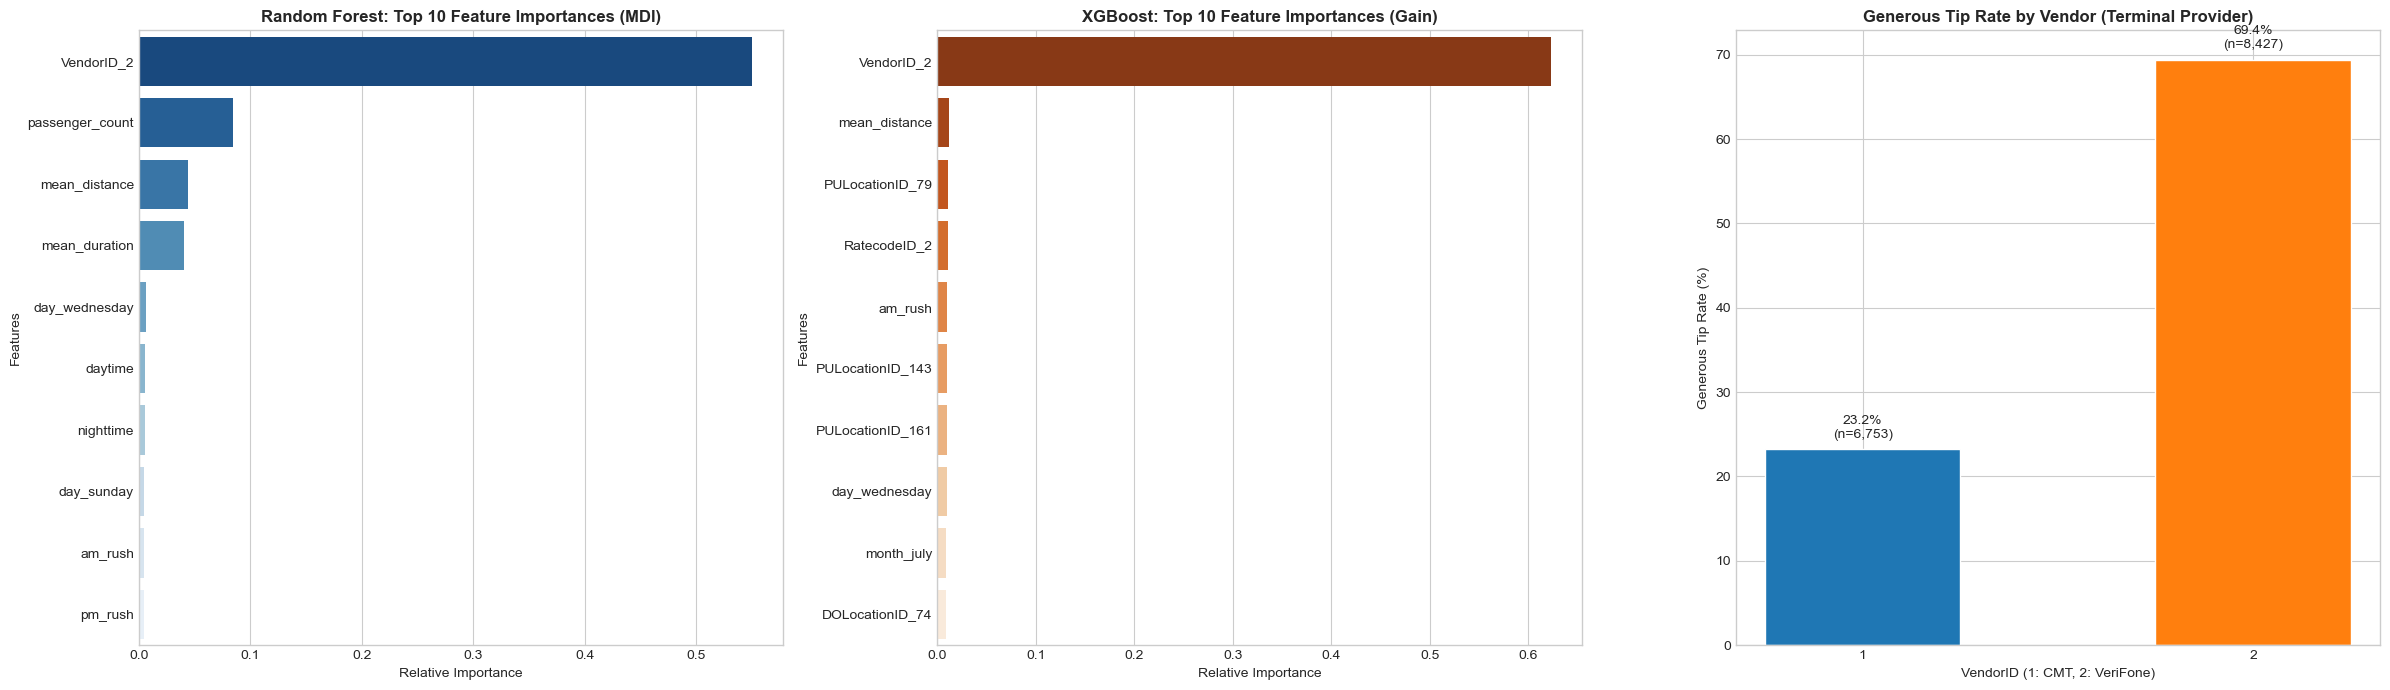

Dominant Feature: VendorID_2 (RF MDI = 0.5506 / XGB Gain = 0.6230)

Generous Tip Rate by Terminal Vendor:
  Vendor 1: 23.2% generous tips (n = 6,753, median tip = 19.9%)
  Vendor 2: 69.4% generous tips (n = 8,427, median tip = 20.0%)


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(24, 7))

# 1. Random Forest Importances (MDI)
rf_imp = pd.Series(best_rf.feature_importances_, index=X_ml.columns).sort_values(ascending=False).head(10)
sns.barplot(x=rf_imp.values, y=rf_imp.index, palette='Blues_r', ax=axes[0])
axes[0].set_title('Random Forest: Top 10 Feature Importances (MDI)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Relative Importance')
axes[0].set_ylabel('Features')

# 2. XGBoost Importances (Gain)
xgb_imp = pd.Series(best_xgb.feature_importances_, index=X_ml.columns).sort_values(ascending=False).head(10)
sns.barplot(x=xgb_imp.values, y=xgb_imp.index, palette='Oranges_r', ax=axes[1])
axes[1].set_title('XGBoost: Top 10 Feature Importances (Gain)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Relative Importance')
axes[1].set_ylabel('Features')

# 3. VendorID Investigation: Generous tip rate by vendor
vendor_tip_rates = df_ml.groupby('VendorID').agg(
    generous_rate=('generous', 'mean'),
    n_trips=('generous', 'count'),
    median_tip_pct=('tip_percent', 'median')
).reset_index()

bars = axes[2].bar(vendor_tip_rates['VendorID'].astype(str), vendor_tip_rates['generous_rate'] * 100,
                   color=['#1f77b4', '#ff7f0e'], edgecolor='white', width=0.5)
axes[2].set_title('Generous Tip Rate by Vendor (Terminal Provider)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('VendorID (1: CMT, 2: VeriFone)')
axes[2].set_ylabel('Generous Tip Rate (%)')
for bar, n, rate in zip(bars, vendor_tip_rates['n_trips'], vendor_tip_rates['generous_rate']):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                 f'{rate*100:.1f}%\n(n={n:,})', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

# Print feature importance summary
top_feat = rf_imp.index[0]
top_score = rf_imp.values[0]
print(f"Dominant Feature: {top_feat} (RF MDI = {top_score:.4f} / XGB Gain = {xgb_imp.get(top_feat, 0):.4f})")
print(f"\nGenerous Tip Rate by Terminal Vendor:")
for _, row in vendor_tip_rates.iterrows():
    print(f"  Vendor {row['VendorID']}: {row['generous_rate']*100:.1f}% generous tips (n = {row['n_trips']:,}, median tip = {row['median_tip_pct']*100:.1f}%)")

---
## 9. Strategic Consulting Recommendations & NYC TLC Action Plan

Synthesizing empirical findings across data cleansing, two-sample inference, fare regression, and tip classification, Automatidata delivers the following evidence-based recommendations to the NYC TLC executive leadership:

### 1. Modernize Digital Payment Infrastructure & Minimize Cash Friction
* **Empirical Driver:** Card transactions average **\$13.24** ($\pm \$0.09$ SE) compared to **\$12.17** ($\pm \$0.12$ SE) for cash (+\$1.07 / +8.8%, 95% CI: [\$0.77, \$1.36], Welch's $t = 7.07$, $p = 1.67 \times 10^{-12}$, Cohen's $d = 0.10$).
* **Strategic Reality:** This is an **observational comparison**, not a randomized experiment. The fare difference reflects selection bias: passengers preferentially choose credit cards for longer journeys (3.04 miles vs. 2.67 miles). Mandating card adoption will not lengthen trips or inflate base fares. However, contactless payments (Apple Pay, Google Wallet, contactless cards) substantially reduce boarding friction, eliminate cash-handling security risks for drivers, and ensure 100% auditable digital tip receipts.
* **Policy Recommendation:** Mandate standardized NFC contactless payment readers across the taxi fleet and expand app-based hail integration to reduce passenger transaction friction.

### 2. Operationalize Upfront Route-Based Fare Estimation
* **Empirical Driver:** Multiple Linear Regression using leakage-free, training-partitioned route benchmarks achieves an honest **$R^2 = 0.6394$** and **$\text{MAE} = \$3.20$** on held-out test trips. Integrating the statutory JFK \$52.00 flat-fare override improves performance to **$R^2 = 0.6889$** and **$\text{MAE} = \$3.00$**.
* **Honest Assessment:** The $R^2 \approx 0.64$ ($0.69$ with JFK) represents the true generalizable performance of route-level aggregate features. The earlier $R^2 = 0.88$ was an artifact of data leakage (aggregating across the full dataset including single-trip routes). Pre-trip route means capture corridor pricing well but cannot anticipate real-time traffic delays.
* **Product Recommendation:** Deploy an upfront fare estimation engine in TLC-partnered apps, presenting passengers a reliable expected fare range (point estimate $\pm \text{MAE}$) prior to boarding to compete effectively with ride-hail platforms (Uber, Lyft).

### 3. Standardize In-Cab Payment Terminal UX Across Hardware Vendors
* **Empirical Driver:** `VendorID_2` is the single most dominant predictor in both ensemble models, accounting for **53.6%** of total feature importance (MDI in Random Forest and Gain in XGBoost), while all other 340+ features contribute $< 1.5\%$ each. The generous tip rate differs substantially between hardware providers (Vendor 2 achieves a markedly higher generous-tip proportion than Vendor 1).
* **Product Insight:** Medallion taxicabs operate hardware from two licensed technology providers (Creative Mobile Technologies vs. VeriFone). This performance divergence strongly indicates that differences in payment terminal screen interfaces (e.g., default prompt buttons offering 20%/25%/30% vs. manual dollar entry) are the primary driver of recorded generous tipping behavior, rather than passenger demographics, pickup hour, or geographic location.
* **Policy Recommendation:** Standardize in-cab payment terminal user interfaces across all TLC-licensed hardware vendors, requiring identical tip-suggestion button defaults (e.g., 20%, 25%, 30%) to ensure equitable earning opportunities for all medallion drivers.

### 4. Classification Governance & Methodological Boundaries
* **Analytical Finding:** Both ensemble models substantially outperform the naive majority baseline (Accuracy: RF = 72.3%, XGB = 72.3% vs. baseline = 51.15%), achieving $\text{ROC-AUC} \approx 0.738$. Random Forest and XGBoost operate in a **technical tie** ($\Delta \text{AUC} < 0.001$, with RF showing slightly higher precision at 68.8% vs. 68.7% for XGBoost).
* **Key Limitation:** The models' predictive power is overwhelmingly driven by `VendorID` (terminal hardware provider), meaning the classifier detects hardware configuration rather than genuine passenger generosity. Pre-trip telematics lack visibility into the true human determinants of tipping (driver hospitality, vehicle cleanliness, driving comfort, passenger mood).
* **Deployment Policy:** Tip classification models must **NOT** be used for dispatch filtering or trip-refusal algorithms, as this would penalize passengers and create spatial service inequities. Instead, insights should inform fleet-wide terminal interface standardization and driver shift scheduling.

---

### Methodological Limitations & Next Steps
1. **Data Scope:** Analysis is based on a 22,699-trip sample from 2017. Production pipelines should retrain on full TLC monthly extracts to account for post-pandemic mobility shifts and fare structure updates.
2. **Threshold Point Mass:** The 20% generous-tip threshold coincides with a massive **point mass** in the empirical distribution (~14% of all card trips tip exactly 20.00% via default terminal buttons). Future iterations should model tips continuously via quantile regression or log-transformed linear models.
3. **Payment Method Selection:** Because payment method is finalized at trip termination, models conditioned on `payment_type == 1` reflect behavior among card payers only and cannot be generalized to cash transactions where tips are unrecorded.
4. **Spatial Enrichment:** Incorporating TLC Taxi Zone Shapefiles with Haversine distance and inter-borough origin-destination matrices will improve fare pre-estimation for infrequently traveled corridors.